In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv(r"C:\Users\AKSHAT KUMAR\logistics-warehousing-analytics\data\synthetic_logistics_operations.csv")
df.shape

(900, 25)

In [5]:
df.head()

,shipment_id,shipment_date,district,warehouse_id,wsp_id,transporter,product_category,distance_km,planned_transit_days,actual_transit_days,...,truck_turnaround_hours,storage_utilization_pct,demand_units,opening_stock_units,receipts_units,closing_stock_units,safety_stock_units,stockout_flag,otif_flag,risk_level
0,SHP-0001,2025-04-01,District B,WH-02,WSP-C,Transporter A,Home Care,53,3.8,2.0,...,5.8,58.4,4332,2264,1810,0,415,0,1,Medium
1,SHP-0002,2025-04-01,District A,WH-01,WSP-C,Transporter E,Stationery,83,6.2,4.8,...,4.7,87.9,3964,4015,808,6000,1029,0,1,Low
2,SHP-0003,2025-04-01,District C,WH-01,WSP-A,Transporter C,Foods,225,11.3,13.6,...,5.0,54.4,3412,1664,811,0,728,0,1,Low
3,SHP-0004,2025-04-02,District B,WH-03,WSP-C,Transporter A,Personal Care,757,22.6,24.1,...,4.3,52.6,3957,1415,982,977,722,0,1,Low
4,SHP-0005,2025-04-02,District B,WH-03,WSP-D,Transporter D,Home Care,417,18.1,19.1,...,3.7,51.6,454,2303,319,824,586,0,1,Medium


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   shipment_id              900 non-null    object 
 1   shipment_date            900 non-null    object 
 2   district                 900 non-null    object 
 3   warehouse_id             900 non-null    object 
 4   wsp_id                   900 non-null    object 
 5   transporter              900 non-null    object 
 6   product_category         900 non-null    object 
 7   distance_km              900 non-null    int64  
 8   planned_transit_days     900 non-null    float64
 9   actual_transit_days      900 non-null    float64
 10  units_shipped            900 non-null    int64  
 11  truck_utilization_pct    900 non-null    float64
 12  freight_cost             900 non-null    float64
 13  freight_cost_per_unit    900 non-null    float64
 14  damage_pct               9

In [8]:
# 3. Data Cleaning and Quality Assessment
df.isnull().sum()

shipment_id                0
shipment_date              0
district                   0
warehouse_id               0
wsp_id                     0
transporter                0
product_category           0
distance_km                0
planned_transit_days       0
actual_transit_days        0
units_shipped              0
truck_utilization_pct      0
freight_cost               0
freight_cost_per_unit      0
damage_pct                 0
truck_turnaround_hours     0
storage_utilization_pct    0
demand_units               0
opening_stock_units        0
receipts_units             0
closing_stock_units        0
safety_stock_units         0
stockout_flag              0
otif_flag                  0
risk_level                 0
dtype: int64

In [9]:
df.duplicated().sum()

0

In [10]:
 df["shipment_id"].duplicated().sum()

0

In [11]:
# Convert shipment date
df["shipment_date"] = pd.to_datetime(df["shipment_date"])
df["shipment_date"].dtype

dtype('<M8[ns]')

In [13]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
shipment_date,900,2025-09-29 12:01:36.000000256,2025-04-01 00:00:00,2025-06-30 18:00:00,2025-09-29 12:00:00,2025-12-29 06:00:00,2026-03-31 00:00:00,NaN
distance_km,900.0,450.144444,50.0,257.75,451.5,643.25,848.0,229.285337
planned_transit_days,900.0,16.731778,3.0,11.3,16.7,22.225,36.5,7.2242
actual_transit_days,900.0,18.461556,2.0,12.7,18.1,24.0,38.8,7.756947
units_shipped,900.0,2623.387778,223.0,1373.75,2642.0,3873.25,4995.0,1401.748778
truck_utilization_pct,900.0,35.889556,20.0,20.0,28.4,46.225,100.0,19.81403
freight_cost,900.0,14920.386889,500.0,8114.585,14460.245,21086.8275,37255.58,8331.112663
freight_cost_per_unit,900.0,10.001756,0.12,2.99,5.59,10.4725,153.53,14.814103
damage_pct,900.0,0.554411,0.01,0.24,0.43,0.7625,2.65,0.434978
truck_turnaround_hours,900.0,3.892111,0.5,2.8,3.8,4.9,9.7,1.591976


In [14]:
print("Negative freight costs:", (df["freight_cost"] < 0).sum())

print("Invalid distances:", (df["distance_km"] <= 0).sum())

print("Invalid truck utilization:",
      ((df["truck_utilization_pct"] < 0) |
       (df["truck_utilization_pct"] > 100)).sum())

print("Invalid damage percentages:",
      ((df["damage_pct"] < 0) |
       (df["damage_pct"] > 100)).sum())

print("Invalid OTIF flags:",
      (~df["otif_flag"].isin([0, 1])).sum())

Negative freight costs: 0
Invalid distances: 0
Invalid truck utilization: 0
Invalid damage percentages: 0
Invalid OTIF flags: 0


In [15]:
# 4. Key Performance Indicator (KPI) Engineering
# Create a working copy
df_analysis = df.copy()

# 1. Freight cost per unit
df_analysis["freight_cost_per_unit_calc"] = (
    df_analysis["freight_cost"] /
    df_analysis["units_shipped"]
)

# 2. Transit delay in days
df_analysis["transit_delay_days"] = (
    df_analysis["actual_transit_days"] -
    df_analysis["planned_transit_days"]
)

# 3. Late shipment indicator
df_analysis["late_shipment_flag"] = (
    df_analysis["transit_delay_days"] > 0
).astype(int)

# 4. Stockout indicator
df_analysis["stockout_flag"] = (
    df_analysis["stockout_flag"].astype(int)
)

# 5. OTIF indicator
df_analysis["otif_flag"] = (
    df_analysis["otif_flag"].astype(int)
)

# Display the newly created metrics
display(
    df_analysis[
        [
            "shipment_id",
            "freight_cost",
            "units_shipped",
            "freight_cost_per_unit_calc",
            "planned_transit_days",
            "actual_transit_days",
            "transit_delay_days",
            "late_shipment_flag",
            "otif_flag",
            "stockout_flag"
        ]
    ].head(10)
)


# Create a working copy
df_analysis = df.copy()

# 1. Freight cost per unit
df_analysis["freight_cost_per_unit_calc"] = (
    df_analysis["freight_cost"] /
    df_analysis["units_shipped"]
)

# 2. Transit delay in days
df_analysis["transit_delay_days"] = (
    df_analysis["actual_transit_days"] -
    df_analysis["planned_transit_days"]
)

# 3. Late shipment indicator
df_analysis["late_shipment_flag"] = (
    df_analysis["transit_delay_days"] > 0
).astype(int)

# 4. Stockout indicator
df_analysis["stockout_flag"] = (
    df_analysis["stockout_flag"].astype(int)
)

# 5. OTIF indicator
df_analysis["otif_flag"] = (
    df_analysis["otif_flag"].astype(int)
)

# Display the newly created metrics
display(
    df_analysis[
        [
            "shipment_id",
            "freight_cost",
            "units_shipped",
            "freight_cost_per_unit_calc",
            "planned_transit_days",
            "actual_transit_days",
            "transit_delay_days",
            "late_shipment_flag",
            "otif_flag",
            "stockout_flag"
        ]
    ].head(10)
)


,shipment_id,freight_cost,units_shipped,freight_cost_per_unit_calc,planned_transit_days,actual_transit_days,transit_delay_days,late_shipment_flag,otif_flag,stockout_flag
0,SHP-0001,1820.23,628,2.898455,3.8,2.0,-1.8,0,1,0
1,SHP-0002,500.00,3914,0.127747,6.2,4.8,-1.4,0,1,0
2,SHP-0003,9839.10,3341,2.944957,11.3,13.6,2.3,1,1,0
3,SHP-0004,20879.57,2306,9.054454,22.6,24.1,1.5,1,1,0
4,SHP-0005,19179.94,2278,8.419640,18.1,19.1,1.0,1,1,0
5,SHP-0006,22174.81,4321,5.131870,21.8,22.7,0.9,1,1,0
6,SHP-0007,10241.38,612,16.734281,9.2,10.7,1.5,1,1,0
7,SHP-0008,5248.31,3547,1.479648,3.5,2.8,-0.7,0,1,0
8,SHP-0009,12427.21,1167,10.648852,13.8,14.5,0.7,1,0,0
9,SHP-0010,2050.24,652,3.144540,6.9,12.7,5.8,1,1,0


,shipment_id,freight_cost,units_shipped,freight_cost_per_unit_calc,planned_transit_days,actual_transit_days,transit_delay_days,late_shipment_flag,otif_flag,stockout_flag
0,SHP-0001,1820.23,628,2.898455,3.8,2.0,-1.8,0,1,0
1,SHP-0002,500.00,3914,0.127747,6.2,4.8,-1.4,0,1,0
2,SHP-0003,9839.10,3341,2.944957,11.3,13.6,2.3,1,1,0
3,SHP-0004,20879.57,2306,9.054454,22.6,24.1,1.5,1,1,0
4,SHP-0005,19179.94,2278,8.419640,18.1,19.1,1.0,1,1,0
5,SHP-0006,22174.81,4321,5.131870,21.8,22.7,0.9,1,1,0
6,SHP-0007,10241.38,612,16.734281,9.2,10.7,1.5,1,1,0
7,SHP-0008,5248.31,3547,1.479648,3.5,2.8,-0.7,0,1,0
8,SHP-0009,12427.21,1167,10.648852,13.8,14.5,0.7,1,0,0
9,SHP-0010,2050.24,652,3.144540,6.9,12.7,5.8,1,1,0


In [16]:
# overall KPI summary

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Shipments",
        "Total Freight Cost",
        "Average Freight Cost per Unit",
        "Average Transit Delay (Days)",
        "Late Shipment Rate (%)",
        "Average Truck Utilization (%)",
        "Average Damage (%)",
        "Average Truck Turnaround (Hours)",
        "Average Storage Utilization (%)",
        "OTIF Rate (%)",
        "Stockout Rate (%)"
    ],
    "Value": [
        len(df_analysis),
        df_analysis["freight_cost"].sum(),
        df_analysis["freight_cost_per_unit_calc"].mean(),
        df_analysis["transit_delay_days"].mean(),
        df_analysis["late_shipment_flag"].mean() * 100,
        df_analysis["truck_utilization_pct"].mean(),
        df_analysis["damage_pct"].mean(),
        df_analysis["truck_turnaround_hours"].mean(),
        df_analysis["storage_utilization_pct"].mean(),
        df_analysis["otif_flag"].mean() * 100,
        df_analysis["stockout_flag"].mean() * 100
    ]
})

display(kpi_summary.round(2))


,Metric,Value
0,Total Shipments,900.00
1,Total Freight Cost,13428348.20
2,Average Freight Cost per Unit,10.00
3,Average Transit Delay (Days),1.73
4,Late Shipment Rate (%),69.00
5,Average Truck Utilization (%),35.89
6,Average Damage (%),0.55
7,Average Truck Turnaround (Hours),3.89
8,Average Storage Utilization (%),70.67
9,OTIF Rate (%),80.78


TRANSPORTER SCORECARD


,transporter,shipments,total_cost,total_units,avg_delay_days,late_rate,truck_utilization,damage_rate,otif_rate,weighted_cost_per_unit
0,Transporter A,146,2259443.45,378005,1.36,65.07,35.16,0.54,84.93,5.98
1,Transporter B,156,2412214.87,399984,1.34,64.74,35.22,0.53,80.13,6.03
2,Transporter C,155,2300536.20,418888,2.16,75.48,35.25,0.64,76.77,5.49
3,Transporter D,140,1993654.09,368270,2.40,75.71,36.36,0.52,82.86,5.41
4,Transporter E,160,2297254.60,416013,1.45,64.38,35.30,0.57,80.00,5.52
5,Transporter F,143,2165244.99,379889,1.73,69.23,38.26,0.50,80.42,5.70


WAREHOUSE SCORECARD


,warehouse_id,shipments,avg_storage_utilization,avg_turnaround_hours,stockout_rate,avg_damage_pct
0,WH-01,165,68.87,3.97,21.21,0.56
1,WH-02,146,71.41,3.86,23.29,0.58
2,WH-03,151,70.15,3.86,23.84,0.51
3,WH-04,145,71.67,3.86,26.90,0.59
4,WH-05,147,70.95,4.14,21.09,0.58
5,WH-06,146,71.26,3.66,20.55,0.51


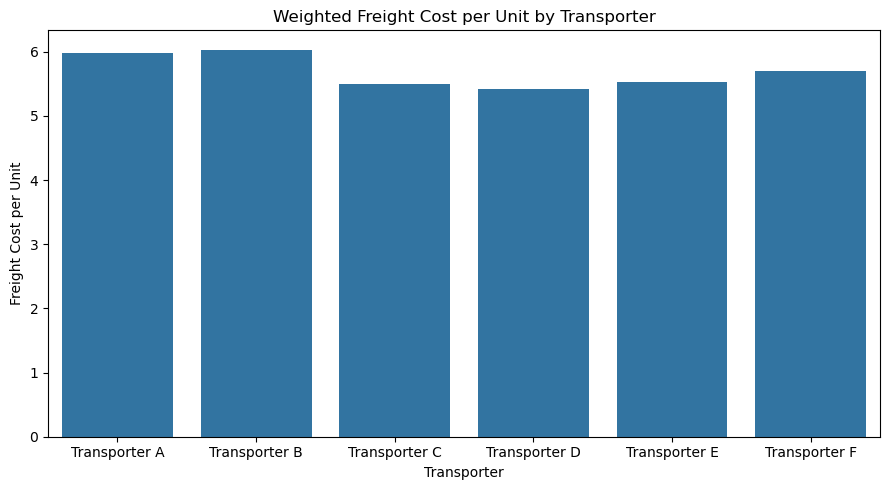

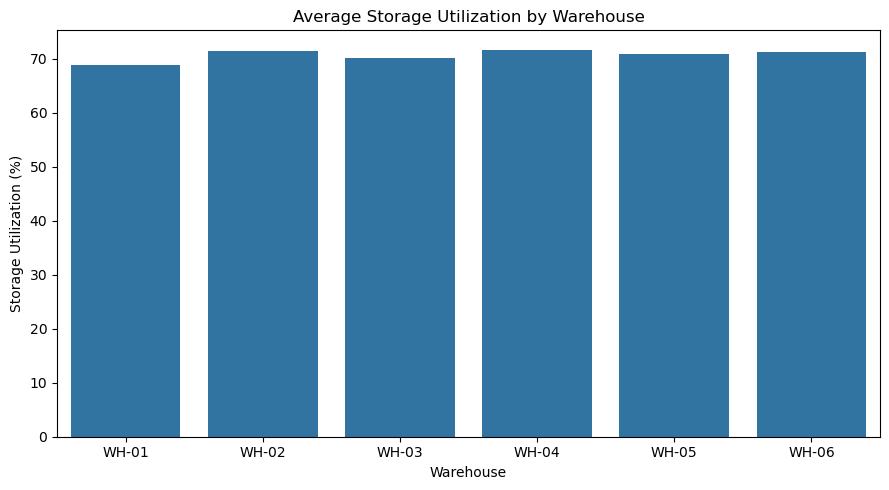

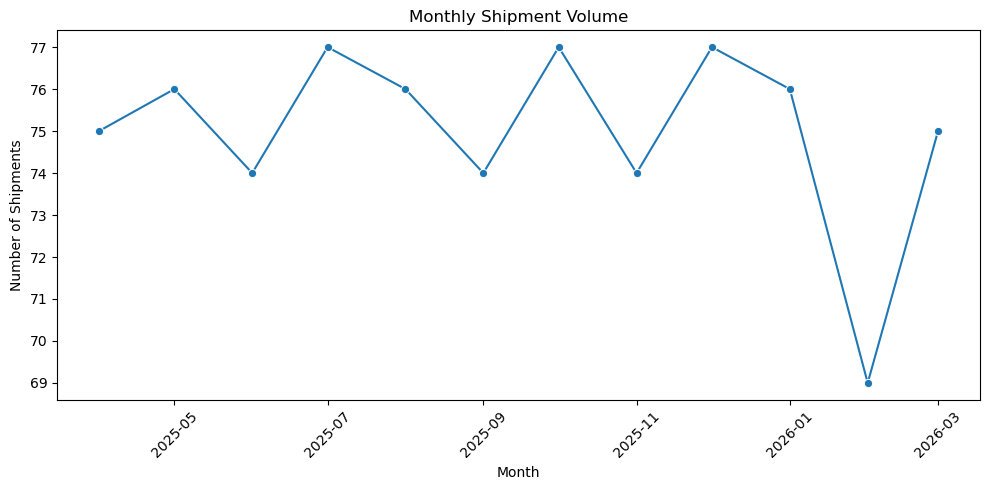

In [19]:

# A. Transporter performance
transporter_summary = (
    df_analysis.groupby("transporter")
    .agg(
        shipments=("shipment_id", "count"),
        total_cost=("freight_cost", "sum"),
        total_units=("units_shipped", "sum"),
        avg_delay_days=("transit_delay_days", "mean"),
        late_rate=("late_shipment_flag", "mean"),
        truck_utilization=("truck_utilization_pct", "mean"),
        damage_rate=("damage_pct", "mean"),
        otif_rate=("otif_flag", "mean")
    )
    .reset_index()
)

transporter_summary["weighted_cost_per_unit"] = (
    transporter_summary["total_cost"] /
    transporter_summary["total_units"]
)

transporter_summary["late_rate"] *= 100
transporter_summary["otif_rate"] *= 100

print("TRANSPORTER SCORECARD")
display(transporter_summary.round(2))


# B. Warehouse performance
warehouse_summary = (
    df_analysis.groupby("warehouse_id")
    .agg(
        shipments=("shipment_id", "count"),
        avg_storage_utilization=("storage_utilization_pct", "mean"),
        avg_turnaround_hours=("truck_turnaround_hours", "mean"),
        stockout_rate=("stockout_flag", "mean"),
        avg_damage_pct=("damage_pct", "mean")
    )
    .reset_index()
)

warehouse_summary["stockout_rate"] *= 100

print("WAREHOUSE SCORECARD")
display(warehouse_summary.round(2))


# C. Visualization 1: Transporter cost comparison
plt.figure(figsize=(9, 5))
sns.barplot(
    data=transporter_summary,
    x="transporter",
    y="weighted_cost_per_unit"
)
plt.title("Weighted Freight Cost per Unit by Transporter")
plt.xlabel("Transporter")
plt.ylabel("Freight Cost per Unit")
plt.tight_layout()
plt.savefig("transporter_cost.png", dpi=150, bbox_inches="tight")
plt.show()


# D. Visualization 2: Warehouse storage utilization
plt.figure(figsize=(9, 5))
sns.barplot(
    data=warehouse_summary,
    x="warehouse_id",
    y="avg_storage_utilization"
)
plt.title("Average Storage Utilization by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Storage Utilization (%)")
plt.tight_layout()
plt.savefig("warehouse_utilization.png", dpi=150, bbox_inches="tight")
plt.show()


# E. Visualization 3: Monthly shipment volume
monthly_shipments = (
    df_analysis.set_index("shipment_date")
    .resample("MS")["shipment_id"]
    .count()
    .reset_index()
)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=monthly_shipments,
    x="shipment_date",
    y="shipment_id",
    marker="o"
)
plt.title("Monthly Shipment Volume")
plt.xlabel("Month")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("monthly_shipments.png", dpi=150, bbox_inches="tight")
plt.show()


In [20]:

from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Users\AKSHAT KUMAR\logistics-warehousing-analytics"
)

TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Save analysis tables
transporter_summary.to_csv(
    TABLES_DIR / "transporter_scorecard.csv", index=False
)

warehouse_summary.to_csv(
    TABLES_DIR / "warehouse_scorecard.csv", index=False
)

kpi_summary.to_csv(
    TABLES_DIR / "overall_kpi_summary.csv", index=False
)

monthly_shipments.to_csv(
    TABLES_DIR / "monthly_shipments.csv", index=False
)

# Save the charts directly to the repository
plt.figure(figsize=(9, 5))
sns.barplot(
    data=transporter_summary,
    x="transporter",
    y="weighted_cost_per_unit"
)
plt.title("Weighted Freight Cost per Unit by Transporter")
plt.xlabel("Transporter")
plt.ylabel("Freight Cost per Unit")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "transporter_cost.png", dpi=150)
plt.close()

plt.figure(figsize=(9, 5))
sns.barplot(
    data=warehouse_summary,
    x="warehouse_id",
    y="avg_storage_utilization"
)
plt.title("Average Storage Utilization by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Storage Utilization (%)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "warehouse_utilization.png", dpi=150)
plt.close()

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=monthly_shipments,
    x="shipment_date",
    y="shipment_id",
    marker="o"
)
plt.title("Monthly Shipment Volume")
plt.xlabel("Month")
plt.ylabel("Shipments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "monthly_shipments.png", dpi=150)
plt.close()

print("Saved analysis tables and figures.")
print("Tables:", list(TABLES_DIR.iterdir()))
print("Figures:", list(FIGURES_DIR.iterdir()))


Saved analysis tables and figures.
Tables: [WindowsPath('C:/Users/AKSHAT KUMAR/logistics-warehousing-analytics/outputs/tables/monthly_shipments.csv'), WindowsPath('C:/Users/AKSHAT KUMAR/logistics-warehousing-analytics/outputs/tables/overall_kpi_summary.csv'), WindowsPath('C:/Users/AKSHAT KUMAR/logistics-warehousing-analytics/outputs/tables/transporter_scorecard.csv'), WindowsPath('C:/Users/AKSHAT KUMAR/logistics-warehousing-analytics/outputs/tables/warehouse_scorecard.csv')]
Figures: [WindowsPath('C:/Users/AKSHAT KUMAR/logistics-warehousing-analytics/outputs/figures/monthly_shipments.png'), WindowsPath('C:/Users/AKSHAT KUMAR/logistics-warehousing-analytics/outputs/figures/transporter_cost.png'), WindowsPath('C:/Users/AKSHAT KUMAR/logistics-warehousing-analytics/outputs/figures/warehouse_utilization.png')]
